# Supplementary Figure 1: Package trajectories

Calculate each selected package's reach as a share of indexed full-text microscopy papers in 2010, 2015, 2020, and 2025. The figure uses a separate vertical scale for each package and marks MATLAB and Jupyter notebooks as scale references.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/literature_yearly.csv` | Yearly package mention counts by source | `python -m census.build.build_dataset` |
| `data/processed/corpus_yearly.csv` | Yearly indexed full-text microscopy denominator | `python -m census.build.build_dataset` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/SFigure1__trajectories.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import sfig1_trajectories as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

The registry query combines each package's aliases with the shared indexed-full-text microscopy context. The yearly query adds the publication year. MATLAB and Jupyter notebooks remain in the per-package display and stay outside field aggregates.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'cellpose', 'matlab']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
12,matlab,MATLAB,"""MATLAB"" AND ((microscopy OR microscope) AND H..."


## Read panel inputs

Load the committed data for the calculations below. Every small panel shows one package trajectory with its own vertical scale. We calculate four-year reach values for six examples before rendering all 30 package panels.

In [3]:
inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')
inspect_processed('tools.csv')

literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io
5,icy,Icy,general-platform,False,True,core,https://icy.bioimageanalysis.org
6,ilastik,ilastik,general-platform,False,True,core,https://www.ilastik.org
7,knime,KNIME,general-platform,False,True,core,https://www.knime.com
8,cellpose,Cellpose,dl-model,True,True,core,https://www.cellpose.org
9,stardist,StarDist,dl-model,True,True,core,https://github.com/stardist/stardist


## Reconstruct panel quantities

Every small panel shows one package trajectory with its own vertical scale. We calculate four-year reach values for six examples before rendering all 30 package panels.

In [4]:
trajectory_tools = ['imagej', 'qupath', 'cellprofiler', 'napari', 'cellpose', 'stardist']
years = [2010, 2015, 2020, 2025]
rows = []
for tool_id in trajectory_tools:
    reach = fs.reach([tool_id])
    for year in years:
        rows.append({'tool_id': tool_id, 'year': year, 'reach_percent': reach.loc[year]})
trajectory = pd.DataFrame(rows)
print(f'Selected trajectory table shape: {trajectory.shape}')
display(trajectory.pivot(index='tool_id', columns='year', values='reach_percent').round(2))

latest = fs.europepmc_yearly().query('year == 2025').set_index('tool_id')['count']
registry_names = registry_table.set_index('tool_id')['name']
display(pd.DataFrame([{'tool_id': tool, 'name': registry_names.loc[tool], 'papers_2025': int(latest.loc[tool]),
                       'reach_2025_percent': fs.reach([tool]).loc[2025]} for tool in trajectory_tools]))

Selected trajectory table shape: (24, 3)


year,2010,2015,2020,2025
tool_id,,,,
cellpose,0.00,0.00,0.01,0.44
cellprofiler,0.10,0.28,0.40,0.58
imagej,10.45,16.89,21.92,27.77
napari,0.00,0.00,0.00,0.16
qupath,0.00,0.00,0.12,0.92
stardist,0.00,0.00,0.01,0.20


,tool_id,name,papers_2025,reach_2025_percent
0,imagej,ImageJ / Fiji,49255,27.771513
1,qupath,QuPath,1625,0.916226
2,cellprofiler,CellProfiler,1032,0.581874
3,napari,napari,278,0.156745
4,cellpose,Cellpose,778,0.438661
5,stardist,StarDist,356,0.200724


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

## Render all panels

Build `SFigure1__trajectories` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote SFigure1__trajectories.png/.pdf/.svg
SFigure1__trajectories: 2074 x 2338 pixels


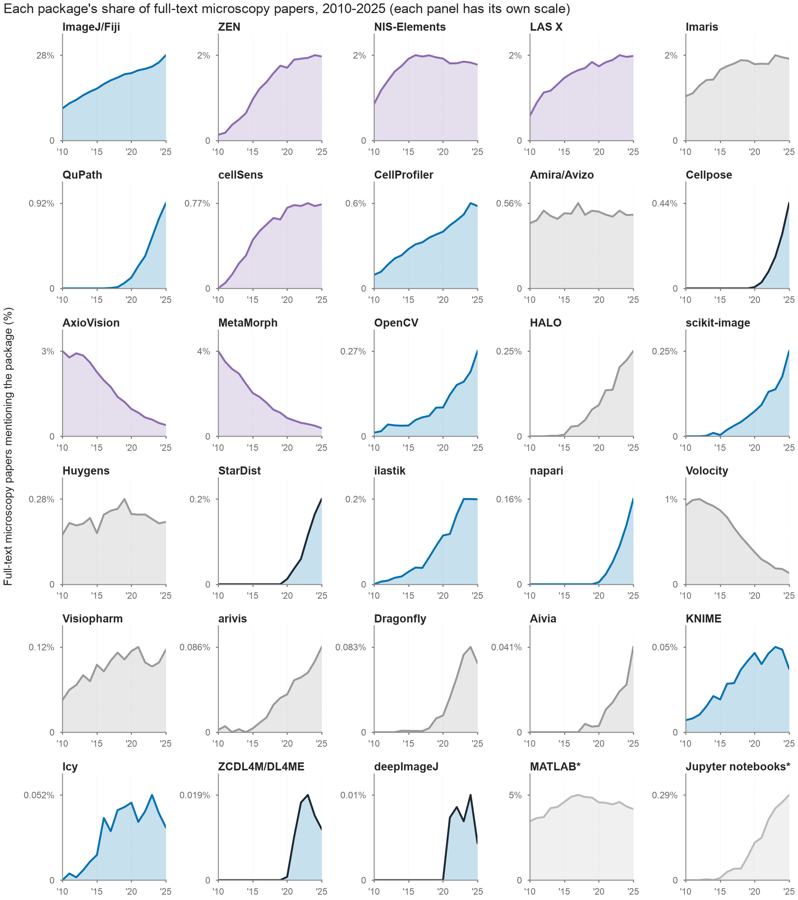

In [5]:
OUTPUT_STEM = 'SFigure1__trajectories'
fig = figure.build_figure()
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


SFigure1__trajectories: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: 27f249725f5b54cdc97393e1284ffceeeecd1814b68abb4ba8ab9fdcfb162d9a
